# Analyse du détecteur ML, version 4 : trois services, trafic réaliste de 2 heures

Les trois services (**shop, auth, payment**) sont maintenant surveillés, avec un modèle **par service**, entraînés sur
2 heures de trafic généré par le Traffic-Generator (profils de visiteurs, comptes, commandes, refus, abandons, rafales).

Le notebook répond à quatre questions :
1. À quoi ressemble le trafic normal de chaque service (volume, part de zéros, refus) ?
2. Chaque modèle (Isolation Forest, LOF, LOF avec bruit, statistique) reste-t-il silencieux sur du trafic normal jamais vu ?
3. Détecte-t-il, **dans le bon service**, un flood sur le shop, un brute force sur auth, un test de cartes sur payment ?
4. Que change la règle « silence » sur les pannes de chaque service ?

Règle de lecture : **score < 0 = photo anormale** (1 photo = 10 s). Une alerte demande 3 photos anormales d'affilée.
Données : `data/normal_2h.csv`. Pour l'exécuter : `uv run jupyter lab` depuis `ML-Detector`.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

import config
from app.domaine import modeles as registre
from app.domaine.detecteur import AnomalyDetector, IncidentTracker
from app.domaine.evaluation import comparer
from app.domaine.silence import DetecteurAvecSilence, RegleSilence

plt.rcParams.update({"figure.figsize": (11, 3.4), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

CHEMIN = RACINE / "data" / "normal_2h.csv"
SHOP, AUTH, PAYMENT = "basecamp-shop", "basecamp-auth", "basecamp-payment"
SERVICES = [SHOP, AUTH, PAYMENT]
REQ = lambda s: f"{s}__req_count"
DENIED = lambda s: f"{s}__denied_count"
NON_SUCCESS = lambda s: f"{s}__non_success_count"
print("Services surveillés :", list(config.SERVICES))

Services surveillés : ['basecamp-payment', 'basecamp-auth', 'basecamp-shop']


## 1. Le trafic normal de chaque service

In [2]:
df = pd.read_csv(CHEMIN)
df["heure"] = pd.to_datetime(df["timestamp"], unit="s", utc=True)
mesures = [c for c in df.columns if "__" in c]
print(f"{len(df)} photos de 10 s = {len(df) * 10 / 60:.0f} min")

lignes = []
for s in SERVICES:
    req = df[REQ(s)]
    lignes.append({"service": s.removeprefix("basecamp-"), "requêtes totales": int(req.sum()),
                   "moyenne / photo": round(req.mean(), 2), "max": int(req.max()),
                   "photos à 0": f"{(req == 0).mean() * 100:.0f} %", "refus totaux": int(df[DENIED(s)].sum())})
pd.DataFrame(lignes).set_index("service")

726 photos de 10 s = 121 min


,requêtes totales,moyenne / photo,max,photos à 0,refus totaux
service,,,,,
shop,9959,13.72,54,0 %,428
auth,1963,2.70,17,47 %,81
payment,298,0.41,8,93 %,5


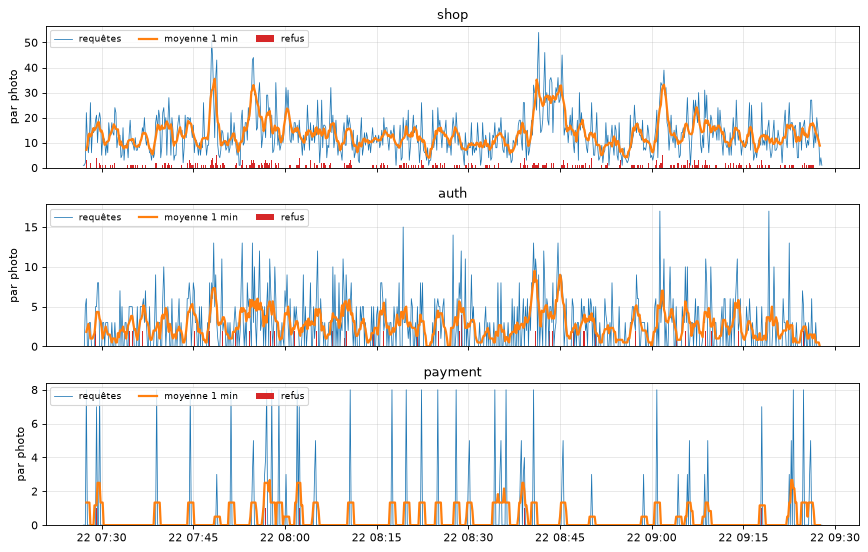

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, s in zip(axes, SERVICES):
    ax.plot(df["heure"], df[REQ(s)], lw=0.7, label="requêtes")
    ax.plot(df["heure"], df[REQ(s)].rolling(6, center=True).mean(), lw=2, label="moyenne 1 min")
    ax.bar(df["heure"], df[DENIED(s)], width=0.0001, color="tab:red", label="refus")
    ax.set(title=s.removeprefix("basecamp-"), ylabel="par photo")
    ax.legend(loc="upper left", ncols=3, fontsize=8)
plt.tight_layout(); plt.show()

**À observer** : `shop` a un trafic soutenu et varié ; `auth` a un trafic moyen avec beaucoup de photos à zéro ;
`payment` est **presque toujours à zéro** (un paiement n'arrive que lorsqu'un client commande, environ 3 % des
sessions). Un modèle appris sur une mesure à 90 % nulle est fragile : on regardera ses fausses alertes de près.
Les rafales légitimes sont visibles comme des pics courts sur le shop.

## 2. Entraînement : un modèle par service

Découpe **dans le temps** : 75 % pour entraîner, 25 % (les plus récentes) pour tester sur du trafic jamais vu.
Quatre types de modèles, entraînés sur les mêmes photos ; `lof_bruit` est un LOF avec un très léger bruit à
l'entraînement (les compteurs entiers produisent beaucoup de points identiques, qui dégénèrent le calcul de densité).

In [4]:
class LOFBruit(registre.LOFModele):
    """LOF avec un bruit infime à l'entraînement pour éviter les distances nulles (usage notebook uniquement)."""
    BRUIT = 0.05

    def fit(self, X):
        self.colonnes = [c for c in X.columns if X[c].std() > 0]
        self.scaler = StandardScaler().fit(X[self.colonnes])
        Z = self.scaler.transform(X[self.colonnes])
        Z = Z + np.random.default_rng(0).normal(0, self.BRUIT, Z.shape)
        self.modele = LocalOutlierFactor(**self.params).fit(Z)
        return self

registre.MODELES_DISPONIBLES["lof_bruit"] = LOFBruit

coupure = int(len(df) * 0.75)
cols = ["timestamp", *mesures]
entrainement = df.loc[:coupure - 1, cols].reset_index(drop=True)
test = df.loc[coupure:, cols].set_index("timestamp")
print(f"entraînement : {len(entrainement)} photos | test : {len(test)} photos")

NOMS = ("isolation_forest", "lof", "lof_bruit", "statistique")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    seuls = {nom: AnomalyDetector(nom).fit(entrainement.drop(columns="timestamp")) for nom in NOMS}
regle = RegleSilence(config.SILENCE_TRAFIC_MIN, config.SILENCE_INTENSITE)
avec = {nom: DetecteurAvecSilence(det, regle) for nom, det in seuls.items()}
detecteurs = {}
for nom in NOMS:
    detecteurs[nom] = seuls[nom]
    detecteurs[f"{nom} + silence"] = avec[nom]

moyennes = seuls["isolation_forest"].moyenne
print("Mesures apprises par service :")
for s, colonnes in seuls["isolation_forest"].features_par_service.items():
    print("  ", s.removeprefix("basecamp-"), [c.split("__")[1] for c in colonnes],
          "| trafic habituel :", round(moyennes[REQ(s)], 2), "req/photo",
          "-> règle silence applicable :", moyennes[REQ(s)] >= regle.trafic_min)

entraînement : 544 photos | test : 182 photos
[info] colonnes ignorées car constantes : ['basecamp-auth__error_logs', 'basecamp-payment__error_logs', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']


[info] colonnes ignorées car constantes : ['basecamp-auth__error_logs', 'basecamp-payment__error_logs', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
[info] colonnes ignorées car constantes : ['basecamp-auth__error_logs', 'basecamp-payment__error_logs', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
[info] colonnes ignorées car constantes : ['basecamp-auth__error_logs', 'basecamp-payment__error_logs', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
Mesures apprises par service :
   auth ['req_count', 'denied_count', 'non_success_count'] | trafic habituel : 2.81 req/photo -> règle silence applicable : False
   payment ['req_count', 'denied_count', 'non_success_count'] | trafic habituel : 0.42 req/photo -> règle silence applicable : False
   shop ['req_count', 'denied_count', 'non_success_count'] | trafic habituel : 13.68 req/photo -> règle silence applicable : True


## 3. Fausses alertes sur du trafic normal jamais vu

In [5]:
def part_anormale(det, service):
    s = det.score(test.copy())[f"score_{service}"]
    return round((s < 0).mean() * 100, 1)

def evenements(det, donnees):
    tracker = IncidentTracker(det, n_consecutifs=config.N_CONSECUTIFS)
    return [ev for ev in (tracker.mettre_a_jour(donnees.iloc[[i]]) for i in range(len(donnees))) if ev]

faux = pd.DataFrame({
    **{f"% photos anormales ({s.removeprefix('basecamp-')})": {n: part_anormale(d, s) for n, d in seuls.items()}
       for s in SERVICES},
    "alertes déclenchées": {n: sum(e["evenement"] == "incident_debut" for e in evenements(d, test))
                            for n, d in seuls.items()},
})
faux

,% photos anormales (shop),% photos anormales (auth),% photos anormales (payment),alertes déclenchées
isolation_forest,0.5,2.7,0.5,0
lof,0.0,1.1,0.0,0
lof_bruit,0.0,1.6,0.5,0
statistique,1.1,1.6,2.2,0


Un modèle utilisable a **0 alerte** sur du trafic normal. Un taux élevé de photos anormales pour `payment` signifie que le
modèle prend l'activité normale de paiement (rare mais légitime) pour une anomalie.

## 4. Quatre incidents injectés, un par service

Chaque incident modifie une fenêtre du jeu de test (trafic réel jamais vu) **dans un seul service** ; le détecteur doit
l'attraper **et désigner le bon service** (colonne `bon_service` du bilan).

| Incident | Service | Ce qui change (30 photos = 5 min, sauf panne) |
|---|---|---|
| **flood** | shop | trafic ×8 + 20 requêtes |
| **brute force** | auth | +25 requêtes par photo dont 22 refus (essais de mot de passe) |
| **test de cartes** | payment | +12 requêtes par photo dont 10 refus (paiements refusés en rafale) |
| **panne 60 s** | shop, auth, payment | 0 requête pendant 6 photos |

In [6]:
DEBUT = 25

def _fenetre(base, debut, duree):
    inc = base.copy()
    f = inc.index[debut:debut + duree]
    inc["_verite"] = ""
    return inc, f

def flood(base, service=SHOP):
    inc, f = _fenetre(base, DEBUT, 30)
    inc.loc[f, REQ(service)] = (inc.loc[f, REQ(service)] * 8 + 20).round()
    inc.loc[f, "_verite"] = service
    return inc, f

def rafale_de_refus(service, requetes, refus):
    def _incident(base):
        inc, f = _fenetre(base, DEBUT, 30)
        inc.loc[f, REQ(service)] = inc.loc[f, REQ(service)] + requetes
        inc.loc[f, DENIED(service)] = inc.loc[f, DENIED(service)] + refus
        inc.loc[f, NON_SUCCESS(service)] = inc.loc[f, DENIED(service)]
        inc.loc[f, "_verite"] = service
        return inc, f
    return _incident

def panne(service, photos=6):
    def _incident(base):
        inc, f = _fenetre(base, DEBUT, photos)
        inc.loc[f, [REQ(service), DENIED(service), NON_SUCCESS(service)]] = 0
        inc.loc[f, "_verite"] = service
        return inc, f
    return _incident

SCENARIOS = {
    "flood (shop)": flood,
    "brute force (auth)": rafale_de_refus(AUTH, 25, 22),
    "test de cartes (payment)": rafale_de_refus(PAYMENT, 12, 10),
    "panne 60 s (shop)": panne(SHOP),
    "panne 60 s (auth)": panne(AUTH),
    "panne 60 s (payment)": panne(PAYMENT),
}
incidents = {nom: fabrique(test) for nom, fabrique in SCENARIOS.items()}

## 5. Les scores au fil du temps (trois attaques, un service chacune)

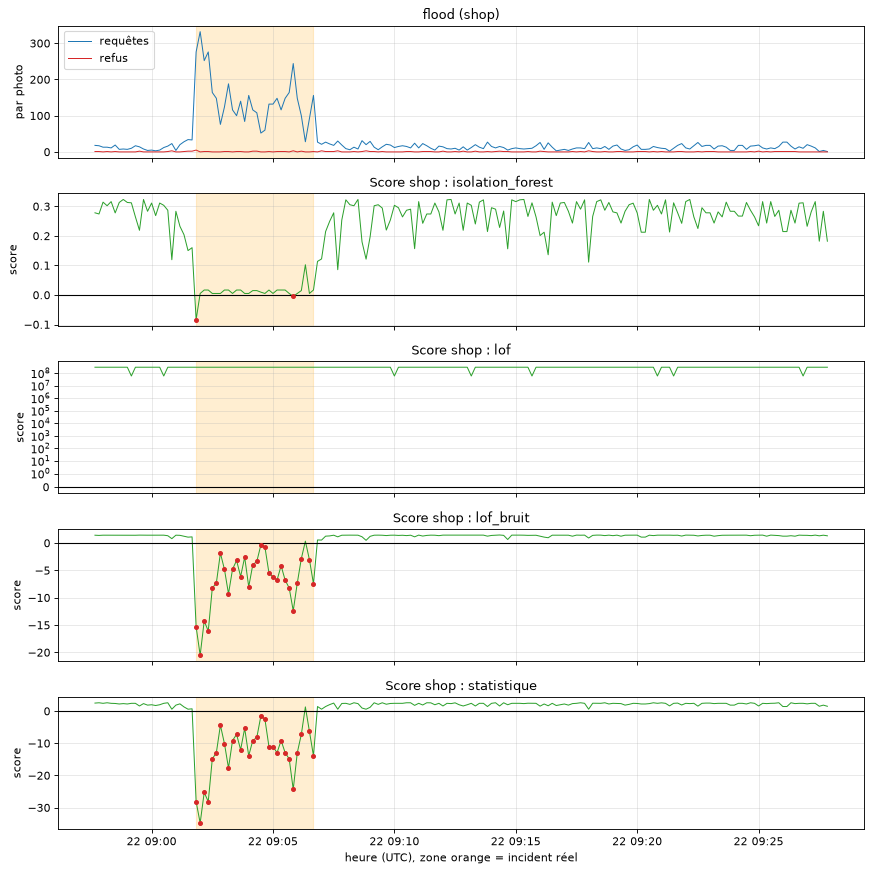

In [7]:
def tracer(nom_scenario, service):
    inc, fenetre = incidents[nom_scenario]
    temps = pd.to_datetime(inc.index, unit="s", utc=True)
    t0, t1 = temps[inc.index.get_loc(fenetre[0])], temps[inc.index.get_loc(fenetre[-1])]
    donnees = inc.drop(columns="_verite")
    fig, axes = plt.subplots(len(NOMS) + 1, 1, figsize=(11, 2.2 * (len(NOMS) + 1)), sharex=True)
    axes[0].plot(temps, inc[REQ(service)], lw=0.9, label="requêtes")
    axes[0].plot(temps, inc[DENIED(service)], lw=0.9, color="tab:red", label="refus")
    axes[0].set(title=f"{nom_scenario}", ylabel="par photo"); axes[0].legend(loc="upper left")
    for ax, nom in zip(axes[1:], NOMS):
        s = seuls[nom].score(donnees)[f"score_{service}"]
        ax.plot(temps, s, lw=0.9, color="tab:green")
        ax.axhline(0, color="black", lw=1)
        anormal = (s < 0).to_numpy()
        ax.scatter(temps[anormal], s.to_numpy()[anormal], color="tab:red", s=12, zorder=3)
        if s.abs().max() > 1000:
            ax.set_yscale("symlog", linthresh=1)
        ax.set(title=f"Score {service.removeprefix('basecamp-')} : {nom}", ylabel="score")
    for ax in axes:
        ax.axvspan(t0, t1, color="orange", alpha=0.18)
    axes[-1].set_xlabel("heure (UTC), zone orange = incident réel")
    plt.tight_layout(); plt.show()

tracer("flood (shop)", SHOP)

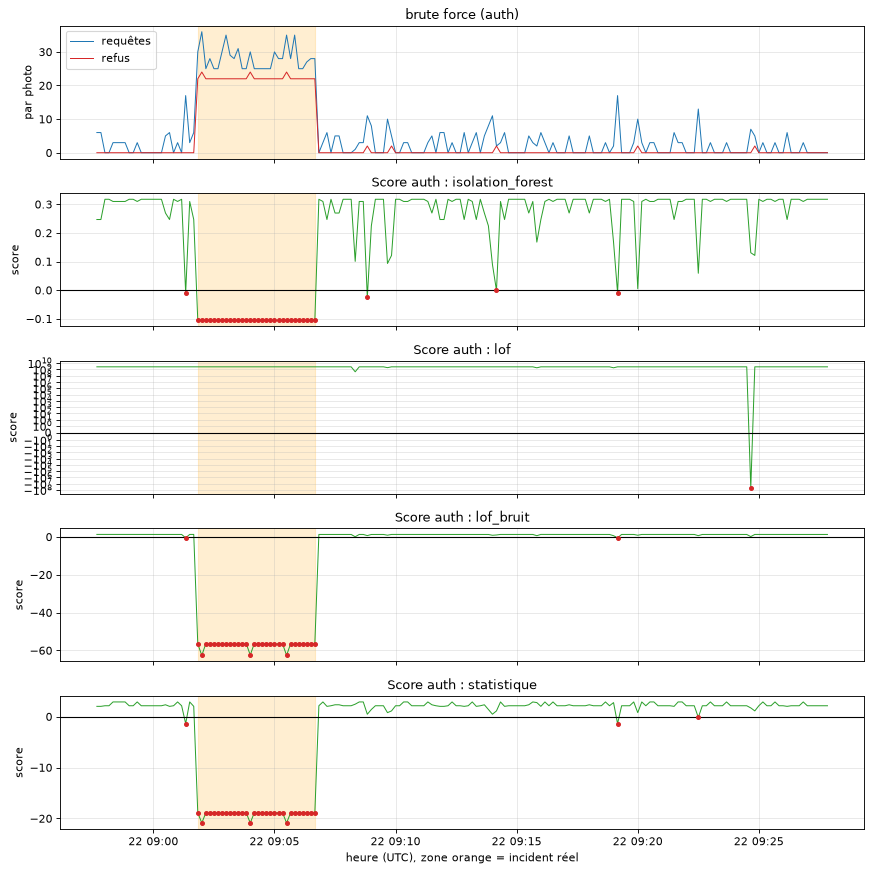

In [8]:
tracer("brute force (auth)", AUTH)

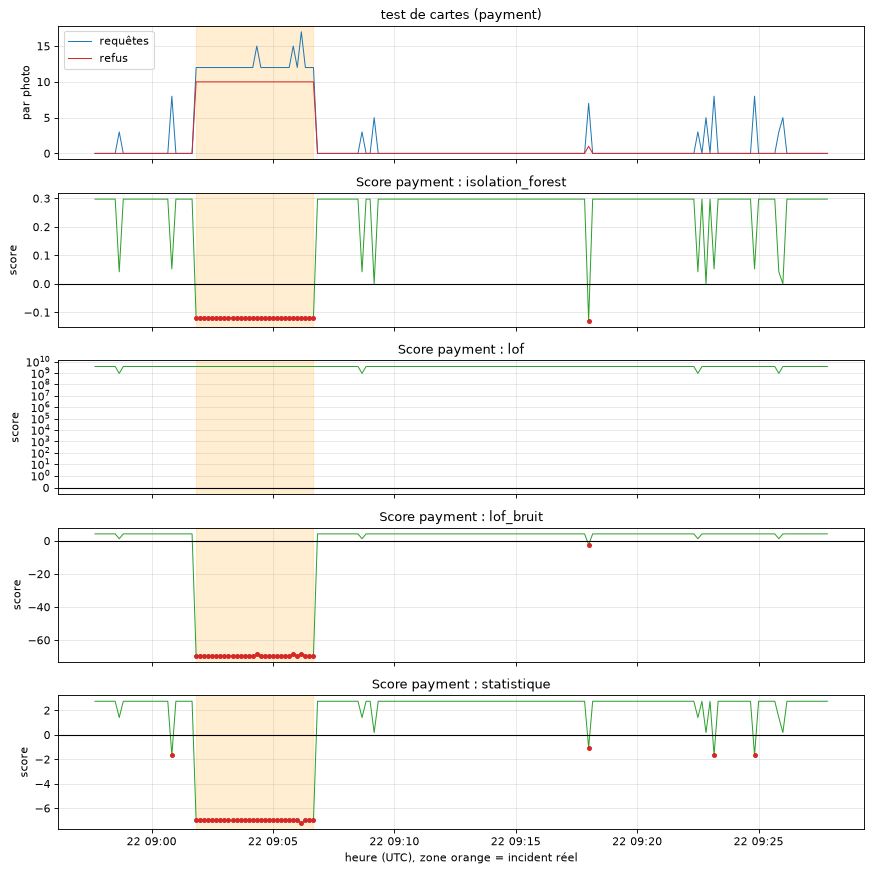

In [9]:
tracer("test de cartes (payment)", PAYMENT)

## 6. Bilan : détection, bon service, délai

In [10]:
def libelle(r):
    if r["type"] != "detecte":
        return "non détecté"
    bon = "" if r["bon_service"] else f" (MAUVAIS service : {r['service_detecte'].removeprefix('basecamp-')})"
    fausse = "" if r["nb_fausses_alertes"] == 0 else " (fausse alerte !)"
    return f"{int(r['delai_s'])} s, {r['gravite']}{bon}{fausse}"

lignes = {}
for nom_scenario, (inc, _) in incidents.items():
    bilan = comparer(inc, detecteurs, n_consecutifs=config.N_CONSECUTIFS).set_index("modele")
    lignes[nom_scenario] = bilan.apply(libelle, axis=1)
tableau = pd.DataFrame(lignes)
tableau

,flood (shop),brute force (auth),test de cartes (payment),panne 60 s (shop),panne 60 s (auth),panne 60 s (payment)
modele,,,,,,
isolation_forest,non détecté,"20 s, critique","20 s, elevee",non détecté,non détecté,non détecté
isolation_forest + silence,non détecté,"20 s, critique","20 s, elevee","20 s, critique",non détecté,non détecté
lof,non détecté,non détecté,non détecté,non détecté,non détecté,non détecté
lof + silence,non détecté,non détecté,non détecté,"20 s, critique",non détecté,non détecté
lof_bruit,"20 s, critique","20 s, critique","20 s, elevee",non détecté,non détecté,non détecté
lof_bruit + silence,"20 s, critique","20 s, critique","20 s, elevee","20 s, critique",non détecté,non détecté
statistique,"20 s, critique","20 s, critique","20 s, elevee",non détecté,non détecté,non détecté
statistique + silence,"20 s, critique","20 s, critique","20 s, elevee","20 s, critique",non détecté,non détecté


Lecture : chaque cellule donne le délai avant l'alerte et la gravité, ou « non détecté ». Une mention « MAUVAIS service »
signifie que l'alerte désigne un autre service que celui touché, ce qui enverrait la remédiation au mauvais endroit.

## 7. Alertes sur le trafic normal, avec et sans la règle silence

In [11]:
pd.DataFrame({
    "alertes (test normal)": {n: sum(e["evenement"] == "incident_debut" for e in evenements(d, test))
                              for n, d in detecteurs.items()},
    "alertes (2 h complètes, en entraînement)": {
        n: sum(e["evenement"] == "incident_debut"
               for e in evenements(d, df[["timestamp", *mesures]].set_index("timestamp")))
        for n, d in detecteurs.items()},
})

,alertes (test normal),"alertes (2 h complètes, en entraînement)"
isolation_forest,0,0
isolation_forest + silence,0,0
lof,0,0
lof + silence,0,0
lof_bruit,0,0
lof_bruit + silence,0,0
statistique,0,1
statistique + silence,0,1


## 8. Le réglage clé de l'Isolation Forest : la contamination

`contamination` est la part des photos d'entraînement que le modèle accepte de juger « bizarres » : elle fixe son seuil.
Avec les rafales légitimes du trafic d'entraînement, les valeurs élevées sont fréquentes ; un seuil trop strict (1 %) laisse
alors passer un flood, car l'Isolation Forest ne distingue pas un très gros pic d'un pic déjà vu à la limite de la plage.
On compare plusieurs réglages sur des incidents de **force variable** (flood ×8, ×3, ×2 du trafic du shop).

In [12]:
def incident_shop(facteur, ajout=0):
    inc, f = _fenetre(test, DEBUT, 30)
    inc.loc[f, REQ(SHOP)] = (inc.loc[f, REQ(SHOP)] * facteur + ajout).round()
    inc.loc[f, "_verite"] = SHOP
    return inc

SCEN_REGLAGE = {
    "flood x8": incident_shop(8, 20), "flood x3": incident_shop(3), "flood x2": incident_shop(2),
    "brute force (auth)": incidents["brute force (auth)"][0], "test de cartes (payment)": incidents["test de cartes (payment)"][0],
}

def premier_debut(det, inc):
    tracker = IncidentTracker(det, n_consecutifs=config.N_CONSECUTIFS)
    donnees = inc.drop(columns="_verite")
    reel = int(inc.index[inc["_verite"] != ""][0])
    for i in range(len(donnees)):
        ev = tracker.mettre_a_jour(donnees.iloc[[i]])
        if ev and ev["evenement"] == "incident_debut":
            return "FAUSSE ALERTE" if ev["timestamp"] < reel else f"{int(ev['timestamp'] - reel)} s"
    return "non détecté"

reglages = {}
for contamination in (0.01, 0.02, 0.03, 0.05, 0.10):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        det = AnomalyDetector("isolation_forest", contamination=contamination, n_estimators=200,
                              random_state=42).fit(entrainement.drop(columns="timestamp"))
    reglages[f"IF contamination={contamination}"] = {
        "alertes sur trafic normal": sum(e["evenement"] == "incident_debut" for e in evenements(det, test)),
        **{nom: premier_debut(det, inc) for nom, inc in SCEN_REGLAGE.items()},
    }
pd.DataFrame(reglages).T

[info] colonnes ignorées car constantes : ['basecamp-auth__error_logs', 'basecamp-payment__error_logs', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']


[info] colonnes ignorées car constantes : ['basecamp-auth__error_logs', 'basecamp-payment__error_logs', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']


[info] colonnes ignorées car constantes : ['basecamp-auth__error_logs', 'basecamp-payment__error_logs', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']


[info] colonnes ignorées car constantes : ['basecamp-auth__error_logs', 'basecamp-payment__error_logs', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']


[info] colonnes ignorées car constantes : ['basecamp-auth__error_logs', 'basecamp-payment__error_logs', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']


,alertes sur trafic normal,flood x8,flood x3,flood x2,brute force (auth),test de cartes (payment)
IF contamination=0.01,0,non détecté,non détecté,non détecté,20 s,20 s
IF contamination=0.02,0,20 s,20 s,20 s,20 s,20 s
IF contamination=0.03,0,20 s,20 s,20 s,20 s,20 s
IF contamination=0.05,0,20 s,20 s,20 s,20 s,20 s
IF contamination=0.1,1,FAUSSE ALERTE,FAUSSE ALERTE,FAUSSE ALERTE,FAUSSE ALERTE,FAUSSE ALERTE


**Constats de l'exécution du 22/10** (726 photos, soit 2 h de trafic ; entraînement 544 photos, test 182) :

- **Trafic normal** : `shop` 13,7 requêtes par photo, `auth` 2,7 (47 % de photos à 0), `payment` 0,41 (93 % de photos à 0).
  Aucun des quatre modèles ne déclenche d'alerte sur du trafic normal jamais vu.
- **Isolation Forest réglée à 1 %** (réglage par défaut) : **le flood n'est pas détecté** (son score reste juste au-dessus de 0),
  le brute force sur auth et le test de cartes sur payment le sont en 20 s. Avec **2 à 5 %** : tous les incidents sont
  détectés en 20 s sans fausse alerte, y compris les floods modérés (×2 et ×3). À 10 % : une fausse alerte apparaît.
- **LOF du code** : dégénéré (les compteurs entiers produisent trop de points identiques), il ne détecte rien. Avec un
  léger bruit (`lof_bruit`), comme la **statistique**, il détecte les trois attaques en 20 s.
- **Pannes de 60 s** : seul le **shop** est couvert, grâce à la règle silence (20 s, gravité critique). `auth` (trafic moyen
  de 2,7 < 3) et `payment` (0,41) échappent à la règle, et à tous les modèles.
- **Bon service désigné** pour toutes les détections (aucune cellule « MAUVAIS service »).

**Limites** : incidents injectés dans du trafic réel (pas de vraies attaques) ; un seul découpage entraînement/test ;
`payment` est presque toujours à zéro, son modèle reste peu fiable ; pas de cycle jour/nuit.